# CDC PTB · итоговая проверка 2023 → 2024

## tl;dr

Выбранная в 02 конфигурация обучается заново на train+validation 2023 года. Оставшаяся часть 2023 года используется только для температурной калибровки четырёх вероятностей. На полном 2024 году в проверенном прогоне CatBoost получил log loss **0,34673** против **0,36037** у частотного контроля; подобранная температура ≈ **1,00**.

## Контекст и методы

Температура сохраняет сумму четырёх вероятностей равной 1 и порядок накопленных рисков `<32`, `<34`, `<37`. Эта проверка временная, но **не слепая**: исходы 2024 года уже изучались в проекте. Нет ID матери, мертворождений, дат начала родов и достоверного разделения spontaneous/indicated PTB. Результат не является персональным недельным риском.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.data.preterm_cdc import OUT
from src.training.preterm_cdc import run_temporal

## Результаты · качество и калибровка

In [4]:
metrics, metadata = run_temporal()
cols = ["dataset", "model", "n", "multiclass_log_loss", "multiclass_brier", "auprc_lt32", "auprc_lt34", "auprc_lt37", "brier_lt32", "brier_lt37"]
display(metrics[cols].round(5))
print("Температура:", round(metadata["temperature"], 3), "; модель:", metadata["family"], "; 2024 записей:", f"{metadata['temporal_test_rows']:,}")

Температура: 0.999 ; модель: catboost ; 2024 записей: 3,512,780


,dataset,model,n,multiclass_log_loss,multiclass_brier,auprc_lt32,auprc_lt34,auprc_lt37,brier_lt32,brier_lt37
0,2024 temporal,prevalence,3512780,0.36037,0.16287,0.01241,0.02152,0.08757,0.01225,0.07990
1,2024 temporal,catboost_raw,3512780,0.34673,0.15860,0.03159,0.05385,0.17550,0.01215,0.07713
2,2024 temporal,catboost_temperature,3512780,0.34673,0.15860,0.03159,0.05385,0.17550,0.01215,0.07713
3,2023 calibration,catboost_raw,696392,0.34518,0.15743,0.03175,0.05324,0.17400,0.01219,0.07656
4,2023 calibration,catboost_temperature,696392,0.34518,0.15743,0.03175,0.05324,0.17400,0.01219,0.07656


In [5]:
test = pd.read_parquet(OUT / "temporal_predictions_2024.parquet")
probs = test[[f"class_{i}" for i in range(4)]].to_numpy(dtype=float)
assert np.allclose(probs.sum(axis=1), 1, atol=2e-6)
risk32 = probs[:, 0]; risk34 = probs[:, :2].sum(axis=1); risk37 = probs[:, :3].sum(axis=1)
assert np.all(risk32 <= risk34 + 1e-8) and np.all(risk34 <= risk37 + 1e-8)
print("Проверка согласованности <32 ≤ <34 ≤ <37: пройдена")

Проверка согласованности <32 ≤ <34 ≤ <37: пройдена


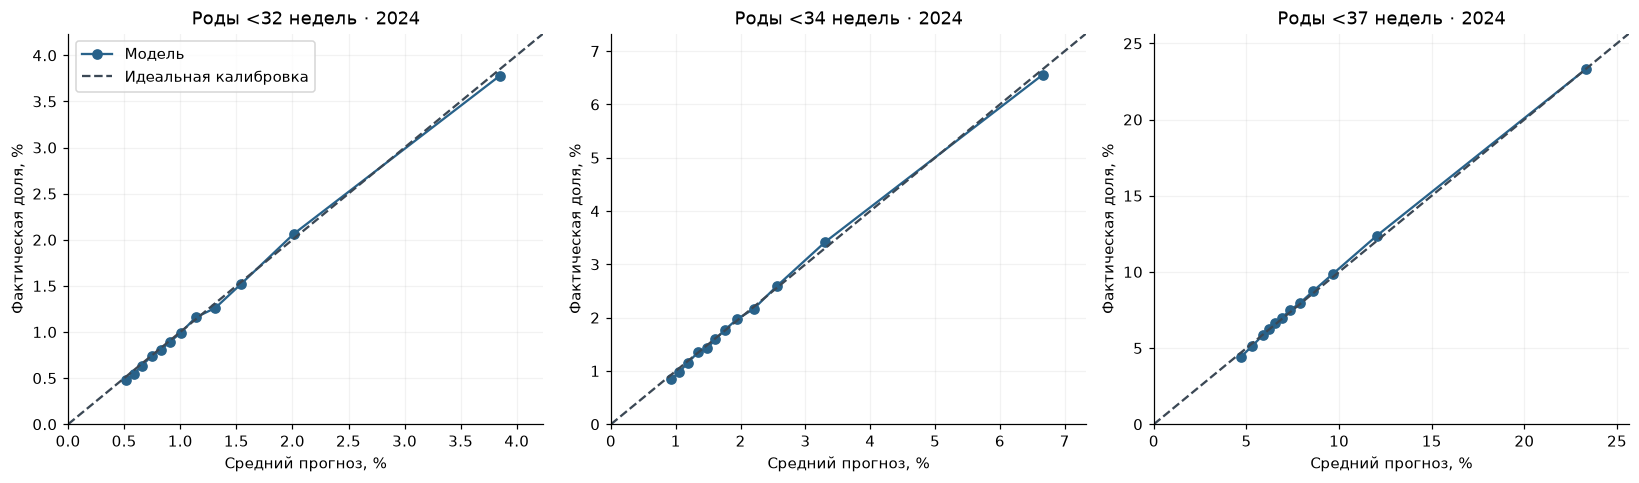

In [6]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, threshold, risk in zip(axes, [32, 34, 37], [risk32, risk34, risk37]):
    observed = (test.risk_band.to_numpy() < {32: 1, 34: 2, 37: 3}[threshold]).astype(int)
    obs, pred = calibration_curve(observed, risk, n_bins=12, strategy="quantile")
    ax.plot(pred * 100, obs * 100, "o-", color=BLUE, label="Модель")
    end = max(pred.max(), obs.max()) * 110
    ax.plot([0, end], [0, end], "--", color=SLATE, label="Идеальная калибровка")
    ax.set(xlim=(0, end), ylim=(0, end), xlabel="Средний прогноз, %", ylabel="Фактическая доля, %", title=f"Роды <{threshold} недель · 2024")
axes[0].legend(); plt.tight_layout(); plt.show()

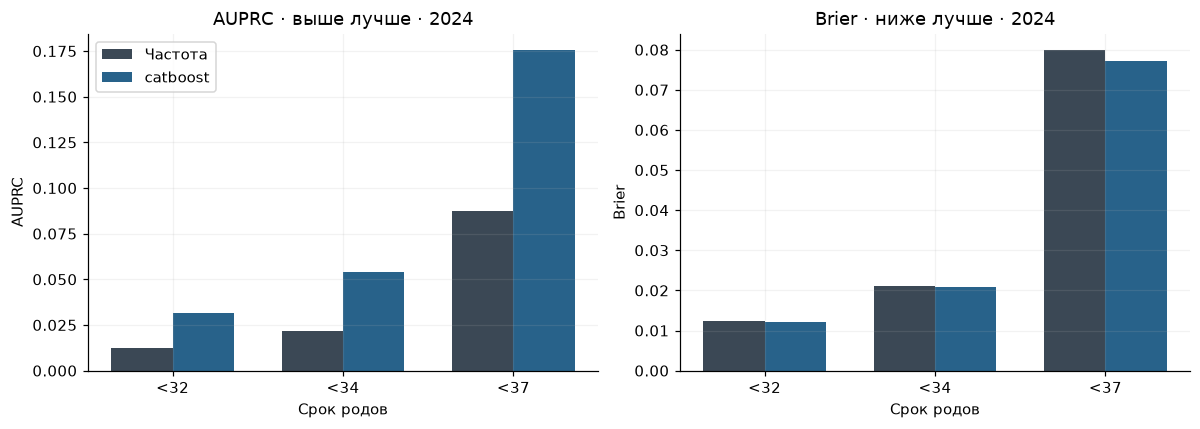

In [7]:
part = metrics.loc[metrics.dataset.eq("2024 temporal")].set_index("model")
model_key = metadata["family"] + "_temperature"
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3); labels = ["<32", "<34", "<37"]
for ax, metric, title in [(axes[0], "auprc", "AUPRC · выше лучше"), (axes[1], "brier", "Brier · ниже лучше")]:
    control = [part.loc["prevalence", f"{metric}_lt{w}"] for w in [32, 34, 37]]
    model = [part.loc[model_key, f"{metric}_lt{w}"] for w in [32, 34, 37]]
    ax.bar(x - .18, control, width=.36, color=SLATE, label="Частота")
    ax.bar(x + .18, model, width=.36, color=BLUE, label=metadata["family"] )
    ax.set_xticks(x, labels)
    ax.set(xlabel="Срок родов", ylabel=metric.upper() if metric == "auprc" else "Brier", title=f"{title} · 2024")
axes[0].legend(); plt.tight_layout(); plt.show()

## Выводы и пределы применения

Сравнивайте модель с частотным контролем и проверяйте прежде всего log loss, Brier и калибровку. AUPRC зависит от частоты исхода. Порог для клинического решения здесь не выбирался. Модель обучена на записях о живорождении в США; перенос на продолжающуюся беременность и персональные недели требует продольной когорты с точным сроком и типом родов.